In [1]:
from photutils.detection import DAOStarFinder
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

In [9]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='viridis',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)
    
def add_stars(xstars,ystars,radius=20,color='r',ax=None):
    ''' this will add circles at the location of xstars,ystars '''
    if ax is None:
        ax = plt.gca()
    allcircles=[]
    #The zip function takes iterables (e.g. lists or arrays) and groups them into tuples that contain 
    #matched pairs of each input, e.g [(x,y)]
    for x,y in zip(xstars,ystars):
        c = plt.Circle((x,y),radius,color=color,fill=False)
        #allcircles.append(c)
        ax.add_artist(c)

### NGC1087

Text(0.5, 1.0, 'NGC 1087 blob model image')

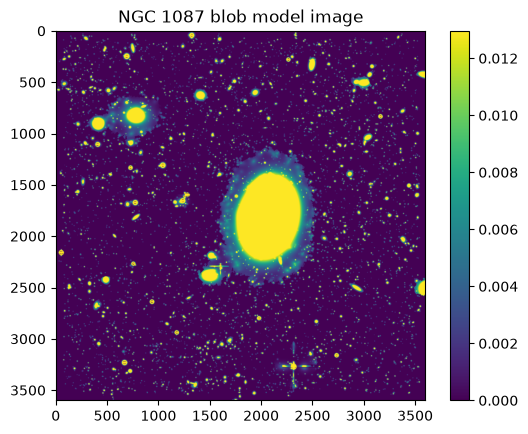

In [19]:
datadir1087 = '/home/m529w976/ASTR596/Capstone_data/NGC1087'
#change directory to the data directory
os.chdir(datadir1087)

#make the figure
plt.figure()

#read in the data and header
data1087,header1087 = fits.getdata('legacysurvey-0416m005-blobmodel-r.fits.fz', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data1087)
plt.title("NGC 1087 blob model image")

In [32]:
target_wcs1087 = WCS(header1087)
print(target_wcs)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 41.625 -0.5
CRPIX : 1800.5 1800.5
CD1_1 CD1_2  : -7.27777777777778e-05 0.0
CD2_1 CD2_2  : 0.0 7.27777777777778e-05
NAXIS : 3600  3600


### NGC 4252

Text(0.5, 1.0, 'NGC 4252 blob model image')

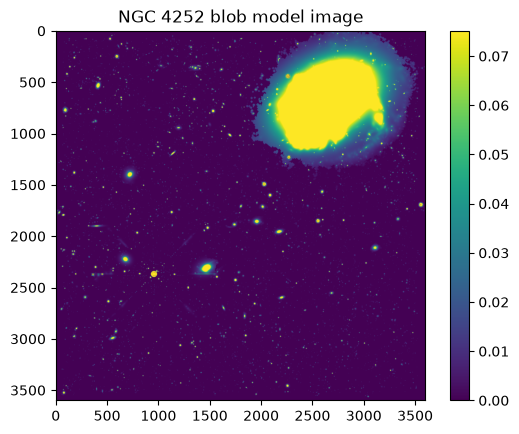

In [33]:
datadir4252 = '/home/m529w976/ASTR596/Capstone_data/NGC4252'
#change directory to the data directory
os.chdir(datadir4252)

#make the figure
plt.figure()

#read in the data and header
data4252,header4252 = fits.getdata('legacysurvey-1847p145-blobmodel-r.fits.fz', header=True)

#use our custom made subroutine from above to plot the image
imdisplay(data4252)
plt.title("NGC 4252 blob model image")

In [31]:
target_wcs4252 = WCS(header1087)
print(target_wcs)

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 184.770773638968 14.5
CRPIX : 1800.5 1800.5
CD1_1 CD1_2  : -7.27777777777778e-05 0.0
CD2_1 CD2_2  : 0.0 7.27777777777778e-05
NAXIS : 3600  3600


### NGC 1385